# 05. Многоклассовая классификация банковских рисков — классический ML

**Задача:** по тексту банковской новости определить один из четырёх классов: `no_risk`, `cyber_risk`, `operational_risk`, `regulatory_risk`. Сравниваются TF-IDF + Logistic Regression и LinearSVC.

**Критерий выбора — Macro F1 на validation.** Test не участвует в подборе алгоритма, представления текста или весов классов. Исходный `bank_risk_dataset.csv` и столбец `split` не изменяются. Поле `found_risk_keywords` исключено из признаков во избежание утечки.

## 1. Импорт, проверка датасета и разбиений

Исходный CSV расположен в `data/`; результаты baseline — в `results/multiclass/baseline/`. Код рассчитан на выполнение из каталога проекта на CPU.

In [1]:
from pathlib import Path
import json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
LABELS = ['no_risk','cyber_risk','operational_risk','regulatory_risk']
ID2LABEL = {i:label for i,label in enumerate(LABELS)}
LABEL2ID = {label:i for i,label in ID2LABEL.items()}
EXPECTED_SHA256 = '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3'

def locate_dataset():
    candidates = [Path.cwd()/'data'/'bank_risk_dataset.csv',
                  Path.cwd()/'bank_risk_dataset.csv',
                  Path.cwd().parent/'data'/'bank_risk_dataset.csv',
                  Path('/kaggle/working/bank_risk_dataset.csv')]
    candidates += sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv')) if Path('/kaggle/input').exists() else []
    present = list(dict.fromkeys(p.resolve() for p in candidates if p.is_file()))
    if not present:
        raise FileNotFoundError('Не найден data/bank_risk_dataset.csv в каталоге проекта или входных данных Kaggle.')
    if len(present)>1:
        valid=[p for p in present if hashlib.sha256(p.read_bytes()).hexdigest()==EXPECTED_SHA256]
        if not valid: raise ValueError(f'Не найден исходный неизменённый CSV среди: {present}')
        return valid[0]
    return present[0]

def load_data():
    path=locate_dataset()
    sha=hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha==EXPECTED_SHA256, 'SHA256 не совпадает с исходным датасетом.'
    df=pd.read_csv(path)
    required={'sample_id','event_group_id','split','title','entity_norm','text_fragment','risk_type_4cls','alert_flag'}
    assert required.issubset(df.columns), f'Не хватает колонок: {required-set(df.columns)}'
    assert len(df)==5041 and df['sample_id'].is_unique
    assert set(df['split'])=={'train','valid','test'}
    assert set(df['risk_type_4cls'])==set(LABELS)
    assert (df['alert_flag'].astype(int) == df['risk_type_4cls'].ne('no_risk').astype(int)).all()
    for col in ('title','entity_norm','text_fragment'):
        df[col]=df[col].fillna('').astype(str)
    assert df['text_fragment'].str.strip().ne('').all()
    parts={s:df[df['split']==s].copy().reset_index(drop=True) for s in ('train','valid','test')}
    assert [len(parts[s]) for s in ('train','valid','test')]==[3535,755,751]
    for a,b in [('train','valid'),('train','test'),('valid','test')]:
        assert not (set(parts[a]['event_group_id']) & set(parts[b]['event_group_id'])), f'Пересечение групп: {a}/{b}'
    print('Датасет:',path,'| SHA256:',sha)
    display(pd.crosstab(df['split'],df['risk_type_4cls']).reindex(index=['train','valid','test'], columns=LABELS))
    return parts,sha

def with_title(title,text):
    title,text=title.strip(),text.strip()
    if not title or title.lower() in text[:max(300,len(title)+40)].lower():
        return text
    return title+'. '+text

def bank_context(bank,text,title):
    sentences=re.split(r'(?<=[.!?])\s+',text.strip())
    words=[w for w in re.findall(r'\w+',bank.casefold()) if len(w)>=4]
    hit=[i for i,s in enumerate(sentences) if bank.casefold() in s.casefold() or any(w in s.casefold() for w in words)]
    if not hit: return with_title(title,text)
    selected=set()
    for i in hit: selected.update(range(max(0,i-1), min(len(sentences),i+2)))
    excerpt=' '.join(sentences[i] for i in sorted(selected))
    return with_title(title,excerpt)

def text_input(frame,mode):
    if mode=='text': return frame['text_fragment'].tolist()
    if mode=='bank_context':
        snippets=[bank_context(b,t,h) for b,t,h in zip(frame['entity_norm'],frame['text_fragment'],frame['title'])]
        # Банк добавляется к тексту; в DL передаётся парой.
        return ['Банк: '+b+'. '+s for b,s in zip(frame['entity_norm'],snippets)]
    raise ValueError(mode)

def evaluate(y_true,y_pred):
    y_true=np.asarray(y_true,dtype=int);y_pred=np.asarray(y_pred,dtype=int)
    f1s=f1_score(y_true,y_pred,labels=list(range(4)),average=None,zero_division=0)
    cm=confusion_matrix(y_true,y_pred,labels=list(range(4)))
    d={'macro_f1':float(f1s.mean()),'risk_macro_f1':float(f1s[1:].mean()),
       'weighted_f1':float(f1_score(y_true,y_pred,average='weighted',zero_division=0)),
       'accuracy':float(accuracy_score(y_true,y_pred)),
       'macro_precision':float(precision_score(y_true,y_pred,labels=list(range(4)),average='macro',zero_division=0)),
       'macro_recall':float(recall_score(y_true,y_pred,labels=list(range(4)),average='macro',zero_division=0)),
       'risk_recall':float(recall_score(y_true,y_pred,labels=[1,2,3],average='macro',zero_division=0))}
    for i,label in enumerate(LABELS): d['f1_'+label]=float(f1s[i])
    d['confusion_matrix']=cm.tolist()
    return d

def save_json(path,obj):
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

parts,DATA_SHA=load_data()

Датасет: D:\bank_risk_diploma_results_v4\bank_risk_diploma_results_v4\data\bank_risk_dataset.csv | SHA256: 52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,3359,74,67,35
valid,715,20,13,7
test,713,17,17,4


## 2. Настройка сравнения

Два представления (`text`, `bank_context`) × два классификатора × фиксированное `class_weight=balanced` = **четыре конфигурации**. Признаки включают слова и символьные n-граммы, что полезно для русскоязычных текстов. Гиперпараметры задаются до просмотра результатов test.

In [2]:
import time, joblib
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report
from itertools import product

SEED=42
OUT=locate_dataset().parent.parent/'results'/'multiclass'/'baseline'
OUT.mkdir(parents=True,exist_ok=True)

def build_pipeline(algorithm,class_weight):
    features=FeatureUnion([
       ('words',TfidfVectorizer(analyzer='word',ngram_range=(1,2),min_df=2,max_features=45000,sublinear_tf=True,dtype=np.float32)),
       ('chars',TfidfVectorizer(analyzer='char',ngram_range=(3,4),min_df=3,max_features=45000,sublinear_tf=True,dtype=np.float32))])
    if algorithm=='LinearSVC': clf=LinearSVC(C=1.0,class_weight=class_weight,random_state=SEED,max_iter=4000)
    else: clf=OneVsRestClassifier(LogisticRegression(C=1.0,class_weight=class_weight,random_state=SEED,max_iter=500,solver='liblinear'))
    return Pipeline([('tfidf',features),('classifier',clf)])

print('Основная метрика: Macro F1 — равный вес всех четырёх классов.')

Основная метрика: Macro F1 — равный вес всех четырёх классов.


## 3. Обучение и оценка на validation

Модели и предсказания сохраняются после оценки на validation. Повторный запуск с теми же файлами пропускает завершённые конфигурации.

In [3]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('once',category=ConvergenceWarning)
records=[]
configs=[(mode,alg,cw) for mode,alg,cw in product(('text','bank_context'),('LinearSVC','LogisticRegression'),('balanced',))]
train_text={mode:text_input(parts['train'],mode) for mode in ('text','bank_context')}
valid_text={mode:text_input(parts['valid'],mode) for mode in ('text','bank_context')}
y_train=parts['train']['risk_type_4cls'].map(LABEL2ID).to_numpy(dtype=int)
y_valid=parts['valid']['risk_type_4cls'].map(LABEL2ID).to_numpy(dtype=int)
for mode,alg,cw in configs:
    name=f'{alg}_{mode}_'+('balanced' if cw else 'standard')
    model_file=OUT/f'{name}.joblib'; metrics_file=OUT/f'{name}_metrics.json'
    if model_file.exists() and metrics_file.exists():
        existing=json.loads(metrics_file.read_text(encoding='utf-8'))
        assert existing['dataset_sha256']==DATA_SHA
        records.append(existing)
        print('Пропущен сохранённый:',name)
        continue
    print('Обучение:',name)
    start=time.monotonic()
    pipe=build_pipeline(alg,cw)
    pipe.fit(train_text[mode],y_train)
    pred=pipe.predict(valid_text[mode])
    met=evaluate(y_valid,pred)
    rec={'name':name,'algorithm':alg,'mode':mode,'class_weight':str(cw or 'none'),
         'dataset_sha256':DATA_SHA,'duration_sec':round(time.monotonic()-start,2),
         **{k:v for k,v in met.items() if k!='confusion_matrix'}}
    save_json(metrics_file,{**rec,'confusion_matrix':met['confusion_matrix']})
    preds=parts['valid'][['sample_id','risk_type_4cls']].copy()
    preds['prediction']=[ID2LABEL[int(i)] for i in pred]
    preds.to_csv(OUT/f'{name}_valid_predictions.csv',index=False)
    joblib.dump(pipe,model_file,compress=3)
    records.append(rec)
comparison=pd.DataFrame(records).sort_values(['macro_f1','risk_macro_f1'],ascending=False).reset_index(drop=True)
comparison.to_csv(OUT/'validation_comparison.csv',index=False)
display(comparison[['name','macro_f1','risk_macro_f1','weighted_f1','macro_precision','macro_recall']].round(4))

Обучение: LinearSVC_text_balanced
Обучение: LogisticRegression_text_balanced
Обучение: LinearSVC_bank_context_balanced
Обучение: LogisticRegression_bank_context_balanced


,name,macro_f1,risk_macro_f1,weighted_f1,macro_precision,macro_recall
0,LogisticRegression_text_balanced,0.7446,0.6642,0.9719,0.8760,0.7177
1,LogisticRegression_bank_context_balanced,0.7381,0.6557,0.9703,0.8733,0.7052
2,LinearSVC_text_balanced,0.6102,0.4856,0.9634,0.6650,0.5784
3,LinearSVC_bank_context_balanced,0.5942,0.4647,0.9604,0.6438,0.5656


## 4. Выбор baseline без обращения к test

Конфигурация выбирается по Macro F1, при равенстве — по Macro F1 трёх классов риска. Метрика этой многоклассовой задачи напрямую не сопоставляется с бинарным F1.

Лучший baseline: LogisticRegression_text_balanced | Macro F1: 0.7446


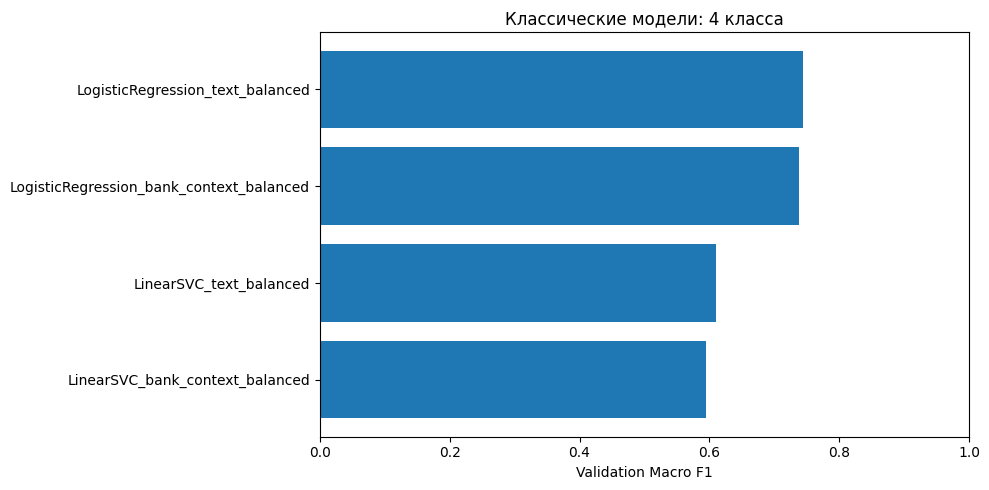

                  precision    recall  f1-score   support

         no_risk       0.98      0.99      0.99       715
      cyber_risk       0.83      0.75      0.79        20
operational_risk       0.69      0.85      0.76        13
 regulatory_risk       1.00      0.29      0.44         7

        accuracy                           0.97       755
       macro avg       0.88      0.72      0.74       755
    weighted avg       0.97      0.97      0.97       755



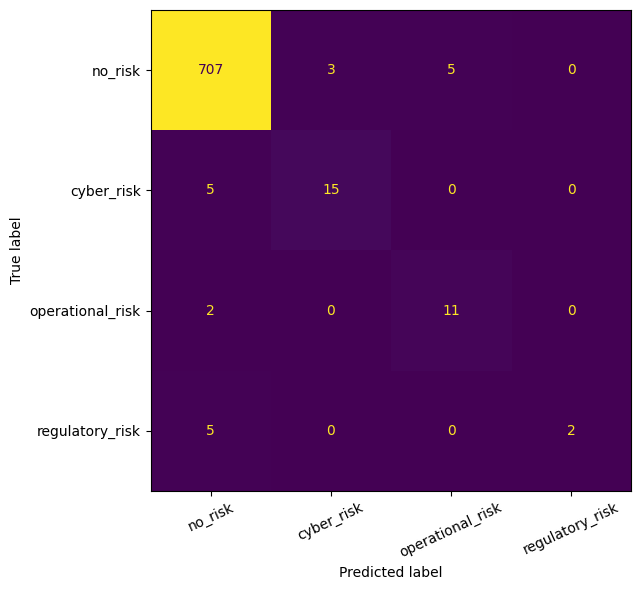

In [4]:
winner=comparison.iloc[0].to_dict()
selected={'task':'risk_type_4cls','criterion':'validation_macro_f1','dataset_sha256':DATA_SHA,
          'name':winner['name'],'validation':{k:float(winner[k]) for k in ('macro_f1','risk_macro_f1','weighted_f1','macro_precision','macro_recall')}}
save_json(OUT/'selection.json',selected)
print('Лучший baseline:',winner['name'],'| Macro F1:',round(winner['macro_f1'],4))
fig,ax=plt.subplots(figsize=(10,5))
sort=comparison.sort_values('macro_f1')
ax.barh(sort['name'],sort['macro_f1']); ax.set_xlim(0,1);ax.set_xlabel('Validation Macro F1');ax.set_title('Классические модели: 4 класса')
fig.tight_layout();fig.savefig(OUT/'baseline_macro_f1.png',dpi=150);plt.show()
selected_valid=pd.read_csv(OUT/f"{winner['name']}_valid_predictions.csv")
print(classification_report(selected_valid['risk_type_4cls'],selected_valid['prediction'],labels=LABELS,zero_division=0))
cm=confusion_matrix(selected_valid['risk_type_4cls'],selected_valid['prediction'],labels=LABELS)
fig,ax=plt.subplots(figsize=(8,6));ConfusionMatrixDisplay(cm,display_labels=LABELS).plot(ax=ax,values_format='d',xticks_rotation=25,colorbar=False)
fig.tight_layout();fig.savefig(OUT/'baseline_validation_cm.png',dpi=150);plt.show()

## 5. Финальная оценка на test

Тестовая оценка отделена от обучения флагом `RUN_FINAL_TEST`. Конфигурация фиксируется по validation Macro F1; подбор параметров по test не предусмотрен. Сохранённая итоговая оценка представлена в ноутбуках 09 и 11.

In [5]:
RUN_FINAL_TEST=False
if RUN_FINAL_TEST:
    path=OUT/'test_metrics.json'
    if path.exists():
        print('Итоговая оценка уже сохранена:',json.loads(path.read_text(encoding='utf-8')))
    else:
        frozen=json.loads((OUT/'selection.json').read_text(encoding='utf-8'))
        pipe=joblib.load(OUT/f"{frozen['name']}.joblib")
        mode='bank_context' if '_bank_context_' in frozen['name'] else 'text'
        test_frame=parts['test']
        y_test=test_frame['risk_type_4cls'].map(LABEL2ID).to_numpy(dtype=int)
        pred=pipe.predict(text_input(test_frame,mode))
        metrics=evaluate(y_test,pred)
        save_json(path,{'name':frozen['name'],'dataset_sha256':DATA_SHA,**metrics})
        pd.DataFrame({'sample_id':test_frame['sample_id'],'true':test_frame['risk_type_4cls'],
                      'pred':[ID2LABEL[int(i)] for i in pred]}).to_csv(OUT/'test_predictions.csv',index=False)
        print('Test Macro F1:',metrics['macro_f1'])
else:
    print('Test отключён; отбор по validation.')

Test не запускался. Выбор проведён исключительно по validation.


## 6. Вывод

Лучший классический вариант — Logistic Regression на текстовых TF-IDF-признаках с балансировкой классов: validation Macro F1 = 0,7446. В отдельной итоговой оценке он получил test Macro F1 = 0,8206 против 0,7329 у основной mDeBERTa. В дополнительной задаче определения категории риска предпочтительна Logistic Regression.